# ResNet (Residual Network) — From Scratch

### Learning objectives

By the end of this notebook, you should be able to:

- explain why ResNet was proposed;
- understand the **degradation problem** in very deep networks;
- explain what a **residual** means;
- understand the equation $H(x)=F(x)+x$;
- distinguish the **main path** from the **shortcut path**;
- understand why ResNet uses **element-wise addition**, not concatenation;
- explain how shortcut connections help **forward information flow**;
- explain how shortcut connections improve **gradient flow during backpropagation**;
- understand the **basic residual block** used in ResNet-18/34;
- understand the **projection shortcut** used when dimensions change;
- understand the **bottleneck block** used in ResNet-50/101/152;
- understand the complete **ResNet-18 architecture**;
- implement ResNet-18 using **TensorFlow / Keras**.

---

## CNN evolution

$$
\boxed{
\text{LeNet}
\rightarrow
\text{AlexNet}
\rightarrow
\text{VGG}
\rightarrow
\text{Inception}
\rightarrow
\text{ResNet}
}
$$

A simple way to remember the progression:

- **LeNet:** early practical CNN.
- **AlexNet:** large-scale CNN with ReLU, dropout and GPU training.
- **VGG:** deeper network using repeated $3\times3$ convolutions.
- **Inception:** parallel branches and multi-scale processing.
- **ResNet:** very deep networks made easier to optimize using shortcut connections.

# 1. Why was ResNet needed?

VGG showed that increasing depth can improve representation learning.

A natural question was:

> If 16 or 19 layers work well, why not use 50, 100 or 150 layers?

But simply stacking more layers caused problems.

### Degradation problem

- A much deeper network can become **harder to optimize**.
- Its training error can even become higher than that of a shallower network.
- This is not simply overfitting, because the problem can appear in the **training error itself**.

ResNet addressed this by introducing:

$$
\boxed{\text{shortcut / skip connections}}
$$

The central idea is to let each block learn a **residual correction** to its input.

# 2. Residual learning

Suppose a block receives an input feature representation:

$$
x
$$

A normal CNN block attempts to directly learn a new mapping:

$$
H(x)
$$

ResNet rewrites the desired mapping as:

$$
H(x)=F(x)+x
$$

Therefore:

$$
F(x)=H(x)-x
$$

Here:

- $x$ = existing input features;
- $F(x)$ = transformation learned by the convolutional path;
- $H(x)$ = output of the residual block.

### Important point

ResNet still learns normal image features such as:

- edges;
- textures;
- shapes;
- object parts;
- higher-level visual patterns.

The convolution layers inside $F(x)$ perform normal pattern learning.

The difference is that their result is interpreted as a **modification of the existing representation** rather than the entire next representation from scratch.

# 3. Basic residual block

The basic block is used in:

- **ResNet-18**
- **ResNet-34**

Its main path contains two $3\times3$ convolutions.

The shortcut carries the original input directly to the addition point.

The final combination is:

$$
\boxed{y=F(x)+x}
$$

## Basic residual block diagram

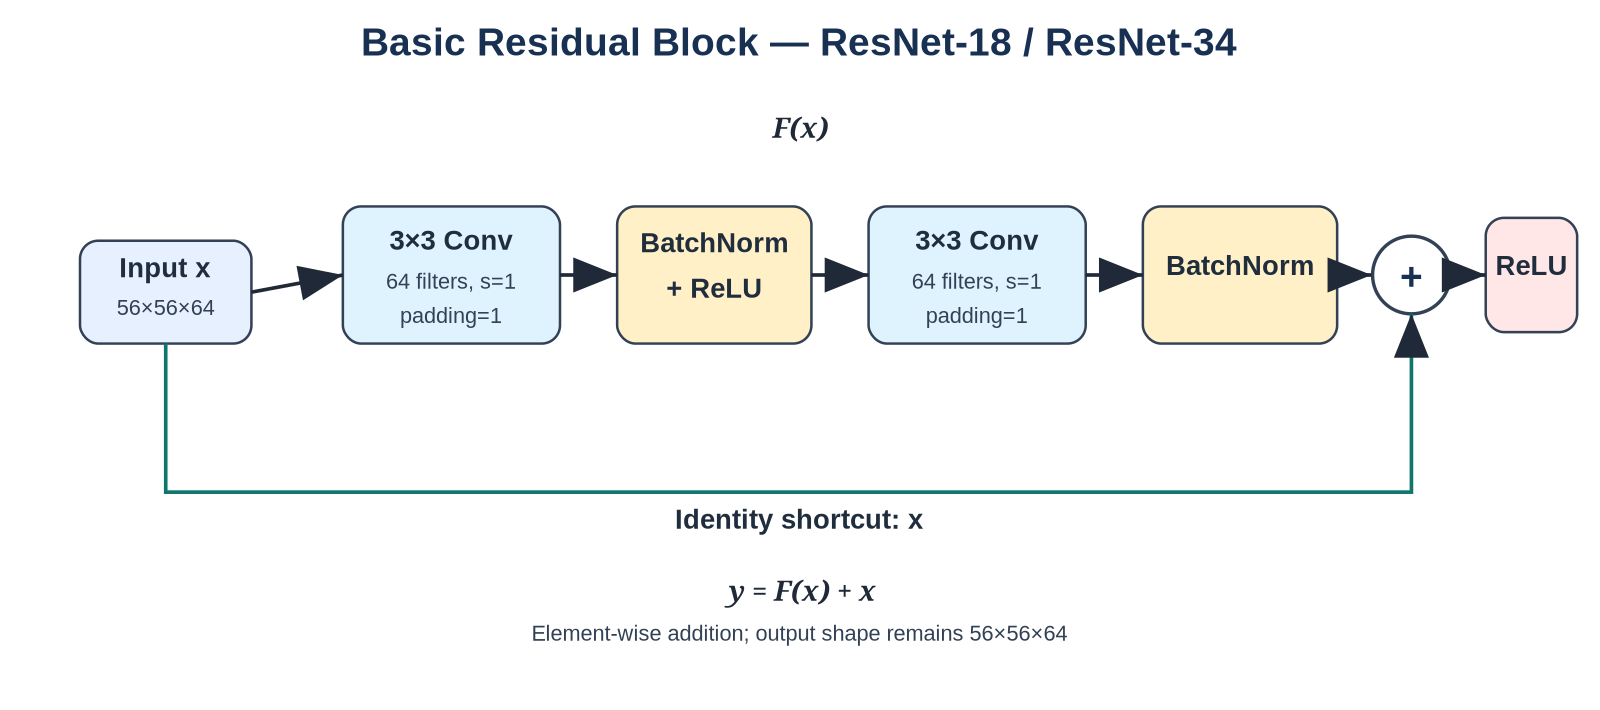

## 4. Numerical example of residual learning

Suppose the input feature vector is:

$$
x=[5,\;2]
$$

Assume the convolutional path learns:

$$
F(x)=[1,\;-0.5]
$$

Then the block output is:

$$
y=x+F(x)
$$

$$
y=[5,\;2]+[1,\;-0.5]
$$

$$
\boxed{y=[6,\;1.5]}
$$

So the convolutional path contributes the **change**:

$$
[1,\;-0.5]
$$

while the existing representation:

$$
[5,\;2]
$$

is carried through the shortcut.

If the input is already close to what is needed, the learned residual may be small:

$$
F(x)\approx0
$$

and therefore:

$$
H(x)\approx x
$$

This makes identity-like behavior easy for the network.

# 5. Addition — not concatenation

In ResNet, the shortcut and main path are combined by **element-wise addition**.

Example:

$$
x=[5,2]
$$

$$
F(x)=[1,-0.5]
$$

Then:

$$
x+F(x)=[6,1.5]
$$

For feature maps:

$$
56\times56\times64
+
56\times56\times64
$$

produces:

$$
\boxed{56\times56\times64}
$$

The shape does not increase.

### Compare with Inception

Inception:

$$
\boxed{\text{parallel branches} \rightarrow \text{concatenate}}
$$

ResNet:

$$
\boxed{\text{main path + shortcut} \rightarrow \text{element-wise add}}
$$

If two feature maps were concatenated instead:

$$
56\times56\times64
\quad\text{and}\quad
56\times56\times64
$$

the result would be:

$$
56\times56\times128
$$

That is **not** what a standard ResNet shortcut does.

# 6. How does the shortcut help in the forward direction?

Consider:

$$
y=F(x)+x
$$

The shortcut carries $x$ directly to the end of the block.

So the next block receives:

$$
\boxed{\text{existing useful features}+\text{new learned refinement}}
$$

The original feature representation does not have to be completely reconstructed by every pair of convolutional layers.

For example, if $x$ already represents:

- edge information;
- texture information;
- useful shape information;

then those features can directly contribute to the block output while $F(x)$ learns additional refinements.

The shortcut therefore provides a direct **information-preserving route** across the block.

# 7. How does the shortcut improve gradient flow?

For a residual block:

$$
y=F(x)+x
$$

Differentiate with respect to $x$:

$$
\frac{\partial y}{\partial x}
=
\frac{\partial F(x)}{\partial x}
+
\frac{\partial x}{\partial x}
$$

Since:

$$
\frac{\partial x}{\partial x}=1
$$

we get:

$$
\boxed{
\frac{\partial y}{\partial x}
=
\frac{\partial F(x)}{\partial x}+1
}
$$

The important term is:

$$
\boxed{+1}
$$

It comes from the identity shortcut.

### Why this matters

In a plain deep network, gradients are repeatedly multiplied by layer derivatives.

For example, if several derivatives are around $0.1$:

$$
0.1\times0.1\times0.1\times0.1=0.0001
$$

the gradient reaching earlier layers can become very small.

In a residual block, the backward signal also has a direct identity path.

Therefore the gradient is not forced to depend only on a long product of transformations.

This does **not guarantee** that gradients can never vanish or explode, but it makes optimization of very deep networks substantially easier.

# 8. Feature-map dimensions in a basic block

Suppose the input is:

$$
56\times56\times64
$$

First convolution:

- kernel = $3\times3$
- filters = 64
- stride = 1
- padding = same

Output:

$$
56\times56\times64
$$

Second convolution also produces:

$$
56\times56\times64
$$

The shortcut contains:

$$
56\times56\times64
$$

So both paths have exactly the same shape and can be added directly.

Therefore:

$$
\boxed{
56\times56\times64
+
56\times56\times64
\rightarrow
56\times56\times64
}
$$

# 9. What happens when dimensions change?

Direct addition requires the two tensors to have the same shape.

Suppose the main path changes:

$$
56\times56\times64
$$

to:

$$
28\times28\times128
$$

Then the original shortcut:

$$
56\times56\times64
$$

cannot be directly added to:

$$
28\times28\times128
$$

ResNet therefore transforms the shortcut using a **projection shortcut**.

A common choice is:

- $1\times1$ convolution;
- stride 2;
- 128 filters.

This converts:

$$
56\times56\times64
\rightarrow
28\times28\times128
$$

Now both paths match.

## Projection shortcut diagram

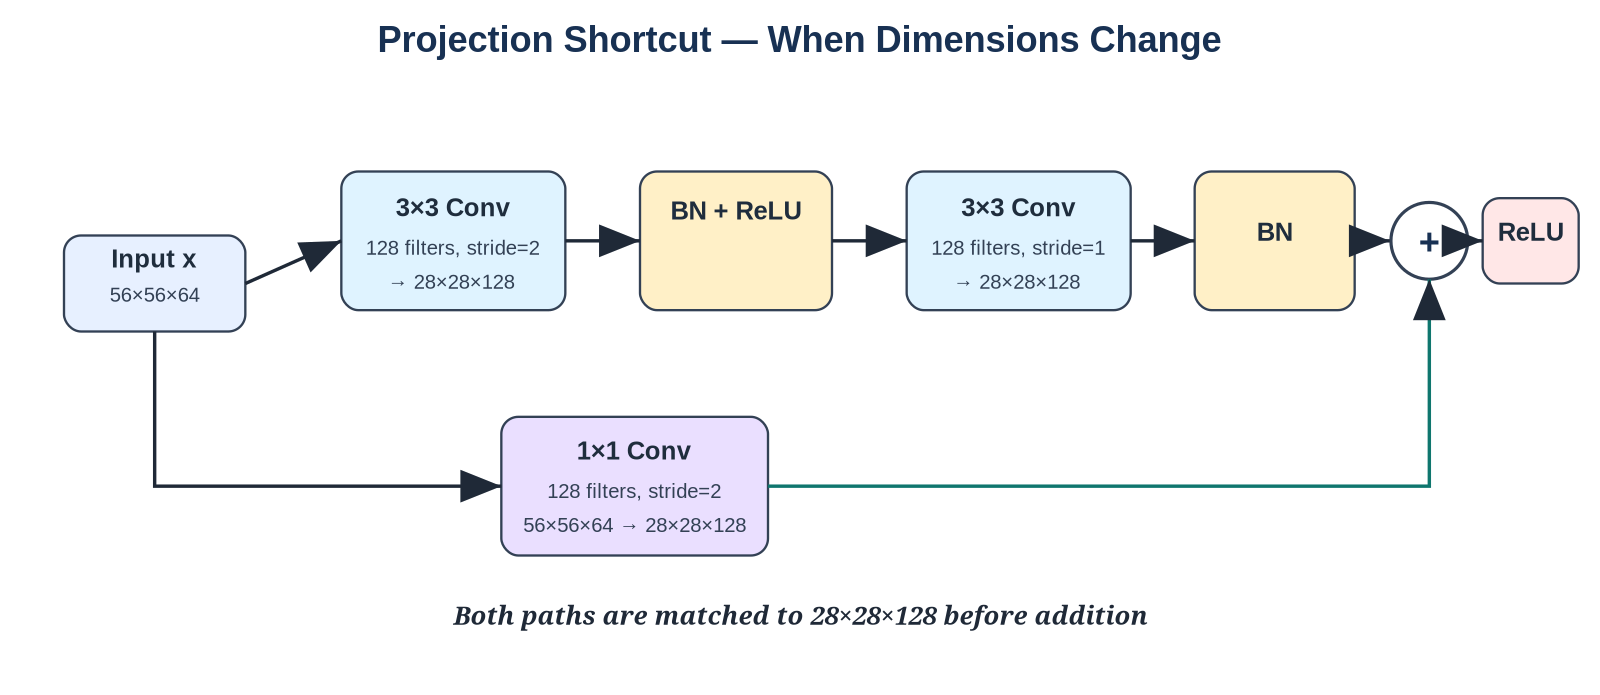

# 10. Why use a $1\times1$ convolution in the projection shortcut?

The purpose here is **shape matching**.

A $1\times1$ convolution can:

- change the number of channels;
- use stride to reduce height and width;
- do both efficiently.

Example:

$$
56\times56\times64
$$

using:

- 128 filters;
- $1\times1$ kernels;
- stride 2;

becomes:

$$
\boxed{28\times28\times128}
$$

Then the shortcut can be added to the main path.

# 11. Bottleneck residual block

Very deep ResNets such as:

- ResNet-50
- ResNet-101
- ResNet-152

use a **bottleneck block**.

Instead of:

$$
3\times3 \rightarrow 3\times3
$$

the bottleneck uses:

$$
\boxed{
1\times1
\rightarrow
3\times3
\rightarrow
1\times1
}
$$

A common channel pattern is:

$$
256\rightarrow64\rightarrow64\rightarrow256
$$

### Roles

First $1\times1$:

- reduces channel depth.

Middle $3\times3$:

- performs spatial feature extraction on fewer channels.

Final $1\times1$:

- expands the channels back.

This makes the expensive $3\times3$ convolution cheaper.

## Bottleneck block diagram

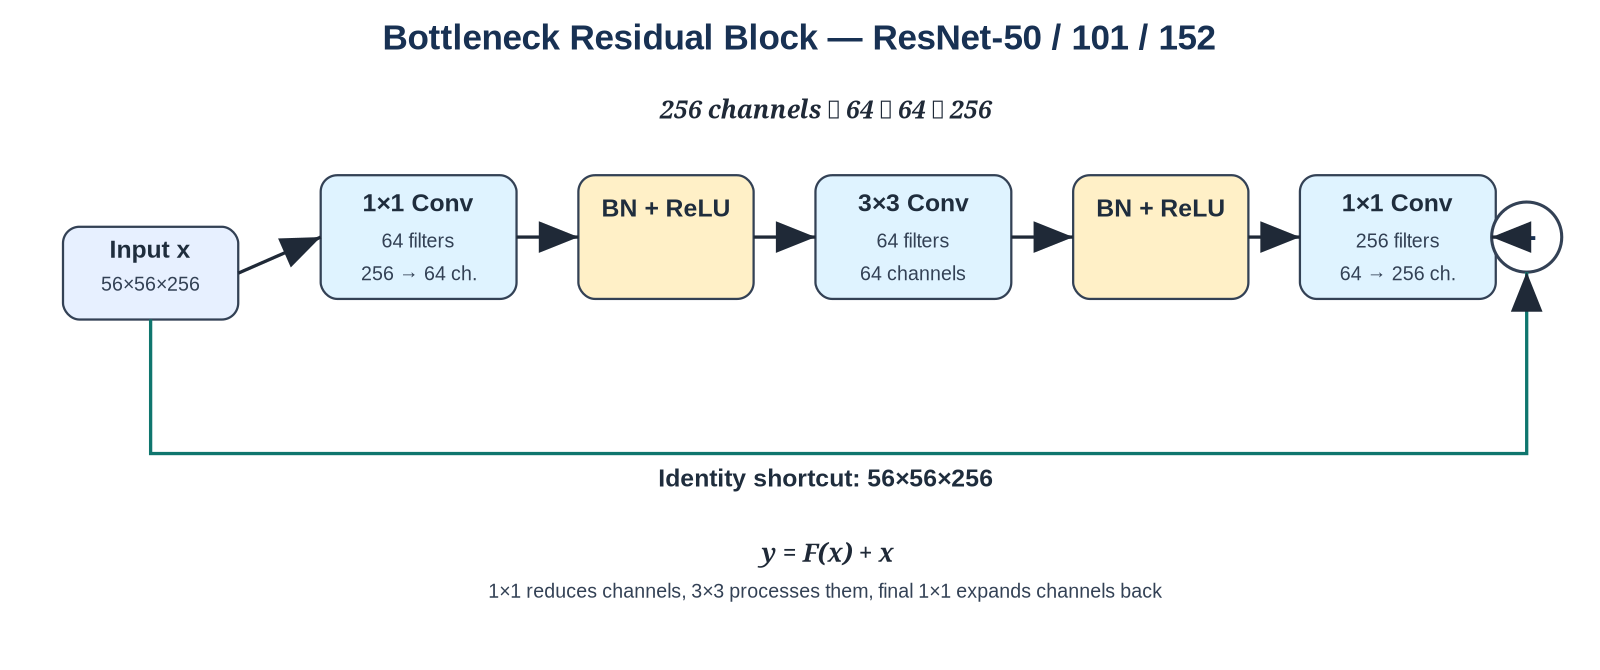

# 12. ResNet-18 architecture

ResNet-18 uses **basic residual blocks**.

Its block pattern is:

$$
\boxed{2,\;2,\;2,\;2}
$$

meaning:

- Stage 1 → 2 basic blocks, 64 channels;
- Stage 2 → 2 basic blocks, 128 channels;
- Stage 3 → 2 basic blocks, 256 channels;
- Stage 4 → 2 basic blocks, 512 channels.

The first block of a new stage usually downsamples the spatial dimensions.

### Main feature-map progression

$$
224\times224\times3
$$

$$
\downarrow
$$

$$
112\times112\times64
$$

$$
\downarrow
$$

$$
56\times56\times64
$$

$$
\downarrow
$$

$$
28\times28\times128
$$

$$
\downarrow
$$

$$
14\times14\times256
$$

$$
\downarrow
$$

$$
7\times7\times512
$$

$$
\downarrow
$$

Global Average Pooling

$$
\downarrow
$$

$$
512
$$

$$
\downarrow
$$

Fully connected classifier.

## Full ResNet-18 architecture diagram

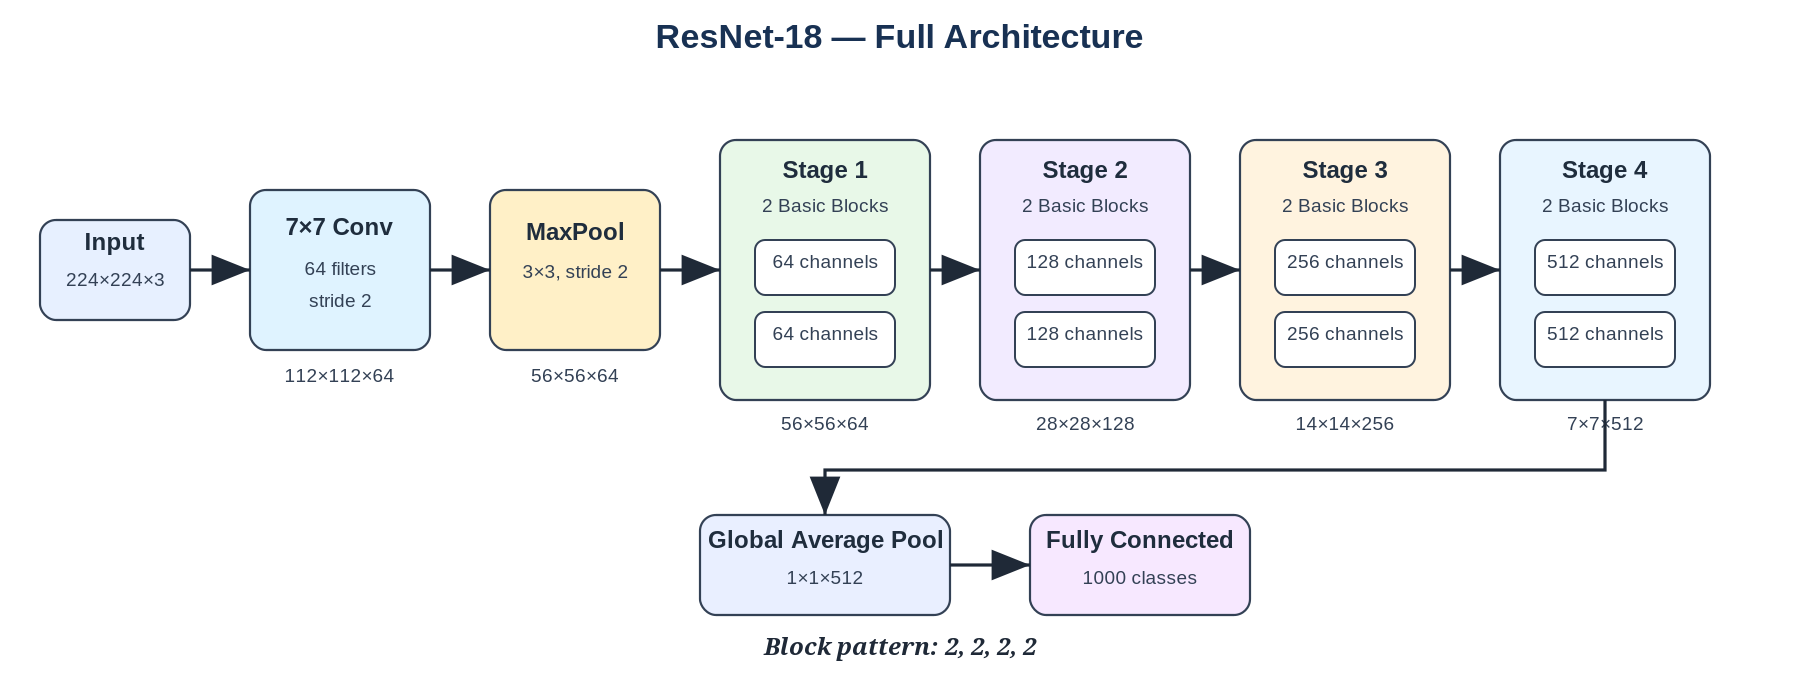

# 13. Why is it called ResNet-18?

Count the main learnable layers.

Initial convolution:

$$
1
$$

There are 8 basic residual blocks.

Each basic block contains 2 convolutions:

$$
8\times2=16
$$

Final fully connected layer:

$$
1
$$

Therefore:

$$
1+16+1=18
$$

Hence:

$$
\boxed{\text{ResNet-18}}
$$

# 14. ResNet-18, ResNet-34 and ResNet-50

| Model | Block type | Blocks per stage |
|---|---|---|
| ResNet-18 | Basic block | 2, 2, 2, 2 |
| ResNet-34 | Basic block | 3, 4, 6, 3 |
| ResNet-50 | Bottleneck block | 3, 4, 6, 3 |
| ResNet-101 | Bottleneck block | 3, 4, 23, 3 |
| ResNet-152 | Bottleneck block | 3, 8, 36, 3 |

The important conceptual distinction is:

$$
\boxed{
\text{ResNet-18/34: }3\times3\rightarrow3\times3
}
$$

$$
\boxed{
\text{ResNet-50+: }1\times1\rightarrow3\times3\rightarrow1\times1
}
$$

# 15. VGG vs Inception vs ResNet

| Architecture | Main idea |
|---|---|
| VGG | Deep sequential stack of mostly $3\times3$ convolutions |
| Inception | Multiple parallel branches + concatenation |
| ResNet | Residual main path + shortcut + addition |

### Easy memory

$$
\boxed{\text{VGG = deeper sequential CNN}}
$$

$$
\boxed{\text{Inception = parallel multi-scale processing}}
$$

$$
\boxed{\text{ResNet = shortcut connections}}
$$

# 16. Implement ResNet-18 using Keras

We will build:

1. a reusable **basic residual block**;
2. a complete **ResNet-18** model.

The implementation uses:

- Conv2D;
- BatchNormalization;
- ReLU;
- element-wise `Add`;
- projection shortcut when shape changes;
- GlobalAveragePooling2D;
- final Dense classifier.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

# 17. Basic residual block in Keras

The block receives:

- the input tensor `x`;
- the number of output filters;
- a stride.

If the shape changes, the shortcut uses a $1\times1$ projection convolution.

In [ ]:
def basic_residual_block(x, filters, stride=1, name="block"):
    shortcut = x

    # Main path: 3x3 Conv -> BN -> ReLU
    y = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=stride,
        padding="same",
        use_bias=False,
        name=f"{name}_conv1"
    )(x)

    y = layers.BatchNormalization(
        name=f"{name}_bn1"
    )(y)

    y = layers.ReLU(
        name=f"{name}_relu1"
    )(y)

    # Main path: second 3x3 Conv -> BN
    y = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=1,
        padding="same",
        use_bias=False,
        name=f"{name}_conv2"
    )(y)

    y = layers.BatchNormalization(
        name=f"{name}_bn2"
    )(y)

    # Projection shortcut when spatial size or channels change
    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters,
            kernel_size=1,
            strides=stride,
            padding="same",
            use_bias=False,
            name=f"{name}_shortcut_conv"
        )(shortcut)

        shortcut = layers.BatchNormalization(
            name=f"{name}_shortcut_bn"
        )(shortcut)

    # Element-wise addition
    y = layers.Add(
        name=f"{name}_add"
    )([y, shortcut])

    # Final activation
    y = layers.ReLU(
        name=f"{name}_out"
    )(y)

    return y

# 18. Build one ResNet stage

A stage contains several residual blocks.

For ResNet-18:

$$
\boxed{2,\;2,\;2,\;2}
$$

The first block of stages 2, 3 and 4 uses stride 2 to reduce the spatial dimensions.

In [ ]:
def make_stage(x, filters, blocks, first_stride, stage_name):
    x = basic_residual_block(
        x,
        filters=filters,
        stride=first_stride,
        name=f"{stage_name}_block1"
    )

    for i in range(2, blocks + 1):
        x = basic_residual_block(
            x,
            filters=filters,
            stride=1,
            name=f"{stage_name}_block{i}"
        )

    return x

# 19. Build the complete ResNet-18 model

In [ ]:
def build_resnet18(input_shape=(224, 224, 3), num_classes=1000):
    inputs = keras.Input(shape=input_shape, name="input_image")

    # Stem
    x = layers.Conv2D(
        64,
        kernel_size=7,
        strides=2,
        padding="same",
        use_bias=False,
        name="conv1"
    )(inputs)

    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.ReLU(name="relu1")(x)

    x = layers.MaxPooling2D(
        pool_size=3,
        strides=2,
        padding="same",
        name="maxpool"
    )(x)

    # Residual stages: 2, 2, 2, 2
    x = make_stage(x, 64,  blocks=2, first_stride=1, stage_name="stage1")
    x = make_stage(x, 128, blocks=2, first_stride=2, stage_name="stage2")
    x = make_stage(x, 256, blocks=2, first_stride=2, stage_name="stage3")
    x = make_stage(x, 512, blocks=2, first_stride=2, stage_name="stage4")

    # Classifier
    x = layers.GlobalAveragePooling2D(
        name="global_average_pool"
    )(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="classifier"
    )(x)

    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="ResNet18"
    )


resnet18 = build_resnet18()
resnet18.summary()

# 20. Check important feature-map dimensions

Expected progression:

```text
Input              → 224×224×3
Conv1              → 112×112×64
MaxPool            → 56×56×64
Stage 1            → 56×56×64
Stage 2            → 28×28×128
Stage 3            → 14×14×256
Stage 4            → 7×7×512
Global Avg Pool    → 512
```

In [ ]:
important_layers = [
    "conv1",
    "maxpool",
    "stage1_block2_out",
    "stage2_block2_out",
    "stage3_block2_out",
    "stage4_block2_out",
    "global_average_pool",
]

shape_model = keras.Model(
    inputs=resnet18.inputs,
    outputs=[
        resnet18.get_layer(name).output
        for name in important_layers
    ]
)

dummy_image = tf.random.normal((1, 224, 224, 3))

outputs = shape_model(dummy_image, training=False)

for name, tensor in zip(important_layers, outputs):
    print(f"{name:24s} -> {tensor.shape}")

# 21. Compile the model

For demonstration, we use Adam and sparse categorical cross-entropy.

This is a convenient teaching setup rather than an exact reproduction of the original ResNet training recipe.

In [ ]:
resnet18.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("ResNet-18 compiled successfully.")

# 22. Test a forward pass

For an ImageNet-style model:

Input:

$$
1\times224\times224\times3
$$

Output:

$$
1\times1000
$$

In [ ]:
dummy_image = tf.random.normal((1, 224, 224, 3))

prediction = resnet18(dummy_image, training=False)

print("Input shape :", dummy_image.shape)
print("Output shape:", prediction.shape)
print("Probability sum:", float(tf.reduce_sum(prediction)))

# 23. Final takeaway

The central ResNet equation is:

$$
\boxed{H(x)=F(x)+x}
$$

Remember:

- $F(x)$ is learned by ordinary convolution layers;
- the shortcut carries $x$ directly;
- the two paths are combined by **element-wise addition**;
- if dimensions differ, use a **projection shortcut**;
- identity shortcuts improve both forward information flow and backward gradient flow;
- ResNet-18 and ResNet-34 use the **basic block**;
- ResNet-50 and deeper variants use the **bottleneck block**.

### One-line comparison

$$
\boxed{
\text{Inception = parallel branches + concatenate}
}
$$

$$
\boxed{
\text{ResNet = residual path + shortcut + add}
}
$$